# 00 — Exploração dos dados negócio a negócio: WDO e WIN

**Objetivo:** antes de aplicar qualquer método do curso, entender os dados. As perguntas são:
- o que é um negócio;
- como o volume se distribui ao longo do dia;
- como são os retornos (caudas, autocorrelação);
- se o fluxo de agressão tem alguma relação com o preço no minuto seguinte.

Conceitos do curso usados aqui: **Cap. 2** ($Y = f(X) + \varepsilon$, predição × inferência) e uma prévia do **Cap. 3** (regressão linear).

**Pré-requisitos:**
```
python -m src.b3_download --dias 30   # baixa os .zip para data/raw/
python -m src.pipeline                # processa um pregão por vez para data/processed/
```

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from statsmodels.graphics.tsaplots import plot_acf

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.pipeline import build, load
from src.features import add_forward_return

plt.rcParams["figure.figsize"] = (11, 4)
build()  # processa só os pregões novos de data/raw/

[]

## 1. Visão geral dos pregões
Cada pregão traz vários vencimentos. O pipeline fica só com o de maior volume (vencimento principal).

In [2]:
summary = load("summary").reset_index()
summary["root"] = summary["ticker"].str[:3]
por_dia = summary.pivot_table(index="day", columns="root", values=["negocios", "contratos"], aggfunc="sum")
print(f"{len(por_dia)} pregões: {por_dia.index.min()} a {por_dia.index.max()}")
por_dia.describe().loc[["mean", "min", "max"]].round(0)

22 pregões: 2026-10-20 a 2026-11-19


contratos               negocios           
root        WDO         WIN        WDO        WIN
mean  3204083.0  20483133.0   744954.0  6584732.0
min   1996720.0  12447691.0   444450.0  5001984.0
max   5017749.0  25371652.0  1338323.0  9345592.0

### O que é um negócio
Cada linha do arquivo é uma execução entre uma corretora compradora e uma vendedora. Uma ordem agressora grande "varre" várias ordens do livro e gera vários negócios no **mesmo milissegundo**. Por isso um negócio não é a mesma coisa que uma ordem.

In [3]:
from src.pipeline import PROCESSED_DIR

rows = []
for f in sorted((PROCESSED_DIR / "trades").glob("*.parquet")):
    t = pd.read_parquet(f, columns=["ts", "root", "qty"])
    for root, g in t.groupby("root", observed=True):
        rajada = g.groupby("ts").size()  # negócios por milissegundo
        rows.append({"dia": f.stem, "ativo": root, "negocios": len(g), "qty_1": (g["qty"] == 1).sum(),
                     "no_mesmo_ms": rajada[rajada > 1].sum(), "maior_rajada": rajada.max()})
neg = pd.DataFrame(rows)
tot = neg.groupby("ativo")[["negocios", "qty_1", "no_mesmo_ms"]].sum()
tot["% de 1 contrato"] = 100 * tot["qty_1"] / tot["negocios"]
tot["% no mesmo ms que outro"] = 100 * tot["no_mesmo_ms"] / tot["negocios"]
pico = neg.loc[neg.groupby("ativo")["maior_rajada"].idxmax()].set_index("ativo")
tot["maior rajada (negócios em 1 ms)"] = pico["maior_rajada"]
tot["dia da maior rajada"] = pico["dia"]
tot.drop(columns=["qty_1", "no_mesmo_ms"]).round(1)

,negocios,% de 1 contrato,% no mesmo ms que outro,maior rajada (negócios em 1 ms),dia da maior rajada
ativo,,,,,
WDO,16171431,67.4,80.1,1643,2026-11-05
WIN,144688252,58.9,77.0,4379,2026-11-05


### Tamanho dos negócios: contagem × volume

A coluna "% de 1 contrato" conta **negócios**: 1 contrato pesa o mesmo que um negócio de 500. Para saber de onde vem o volume, a tabela abaixo pondera cada negócio pelo número de contratos.

Lembrete: um negócio de 1 contrato não é uma ordem de 1 contrato. Uma compra a mercado de 20 contratos que encontra 20 ordens de 1 no livro vira 20 negócios de 1.

In [4]:
t = pd.concat([pd.read_parquet(f, columns=["root", "qty"]) for f in sorted((PROCESSED_DIR / "trades").glob("*.parquet"))])
tamanhos = {}
for root, g in t.groupby("root", observed=True):
    faixa = pd.cut(g["qty"], [0, 1, 5, 10, 50, np.inf], labels=["1", "2-5", "6-10", "11-50", "> 50"])
    tamanhos[(root, "% dos negócios")] = 100 * faixa.value_counts(normalize=True, sort=False)
    tamanhos[(root, "% do volume")] = 100 * g["qty"].groupby(faixa, observed=False).sum() / g["qty"].sum()
    print(f"{root}: média {g['qty'].mean():.1f} contratos por negócio, mediana {g['qty'].median():.0f}, "
          f"maior negócio {g['qty'].max():,}")
pd.DataFrame(tamanhos).rename_axis("contratos no negócio").round(1)

WDO: média 4.3 contratos por negócio, mediana 1, maior negócio 30,000


WIN: média 3.1 contratos por negócio, mediana 1, maior negócio 25,000


WDO                        WIN            
                     % dos negócios % do volume % dos negócios % do volume
contratos no negócio                                                      
1                              67.4        15.6           58.9        18.9
2-5                            18.7        13.1           28.4        28.3
6-10                            6.2        12.1            7.8        19.9
11-50                           6.9        37.8            4.8        27.6
> 50                            0.8        21.4            0.2         5.2

**O que os números mostram**
- Os negócios de 1 contrato são a maioria (67% no WDO e 59% no WIN), mas movimentam só 15–19% do volume.
- No **WDO**, o volume vem dos negócios grandes. Menos de 8% dos negócios (os de 11 contratos ou mais) carregam ~60% dos contratos.
- No **WIN**, o volume é mais espalhado entre os tamanhos.
- A média (4,3 e 3,1 contratos) fica bem acima da mediana (1): a distribuição do tamanho é muito assimétrica, com cauda longa.
- Os maiores negócios passam de 20 mil contratos (30.000 no WDO e 25.000 no WIN). Os gráficos logo abaixo mostram a assimetria, e a seção "Quem fecha os negócios gigantes" mostra de onde eles vêm.

### A forma da distribuição

Três gráficos para a mesma pergunta:
1. **Histograma** dos tamanhos de 1 a 30 contratos: a massa está toda no começo.
2. **P(tamanho ≥ x) em escala log-log:** para cada tamanho x, a fração de negócios com pelo menos x contratos. Esse gráfico (a *função de sobrevivência*, ou CCDF) é o jeito usual de olhar caudas. Numa distribuição de cauda curta, a curva despenca. Numa de cauda longa, ela desce devagar e chega a tamanhos enormes.
3. **Curva de concentração:** ordenando os negócios do maior para o menor, que fração do volume os x% maiores carregam?

WDO: os 0.1% maiores negócios carregam 9% do volume
WDO: os 1% maiores negócios carregam 24% do volume
WIN: os 0.1% maiores negócios carregam 4% do volume
WIN: os 1% maiores negócios carregam 14% do volume


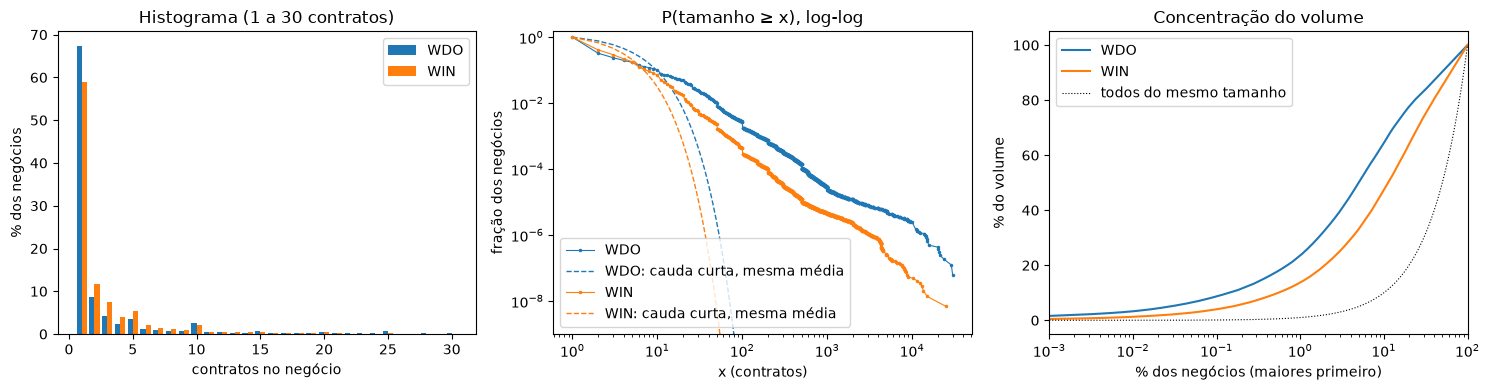

In [5]:
# quantos negócios de cada tamanho, por ativo (t foi carregado na célula da tabela acima)
cont = t.groupby(["root", "qty"], observed=True).size()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for root in ["WDO", "WIN"]:
    n = cont.loc[root]                                          # negócios por tamanho
    q = n.index.to_numpy()
    axes[0].bar(q[q <= 30] + (-0.2 if root == "WDO" else 0.2), 100 * n[n.index <= 30] / n.sum(), width=0.4, label=root)
    sobrev = n[::-1].cumsum()[::-1] / n.sum()                   # P(tamanho >= q)
    linha = axes[1].loglog(q, sobrev, ".-", ms=3, lw=0.8, label=root)[0]
    # referência de cauda curta: geométrica (a "exponencial" dos inteiros) com a mesma média de contratos
    media = (n * n.index).sum() / n.sum()
    x = np.arange(1, 201)
    axes[1].loglog(x, (1 - 1 / media) ** (x - 1), "--", color=linha.get_color(), lw=1,
                   label=f"{root}: cauda curta, mesma média")
    desc = n[::-1]                                              # do maior para o menor
    frac_neg = desc.cumsum() / n.sum()
    frac_vol = (desc * desc.index).cumsum() / (n * n.index).sum()
    axes[2].plot(100 * frac_neg, 100 * frac_vol, label=root)
    for corte in [0.001, 0.01]:
        v = np.interp(corte, frac_neg, frac_vol)
        print(f"{root}: os {100 * corte:g}% maiores negócios carregam {100 * v:.0f}% do volume")
axes[0].set(title="Histograma (1 a 30 contratos)", xlabel="contratos no negócio", ylabel="% dos negócios")
axes[1].set(title="P(tamanho ≥ x), log-log", xlabel="x (contratos)", ylabel="fração dos negócios", ylim=(1e-9, 1.5))
axes[2].set(title="Concentração do volume", xlabel="% dos negócios (maiores primeiro)", ylabel="% do volume", xscale="log")
ref = np.logspace(-3, 2, 200)
axes[2].plot(ref, ref, "k:", lw=0.8, label="todos do mesmo tamanho")
axes[2].set_xlim(0.001, 100)
for ax in axes:
    ax.legend()
plt.tight_layout()

**O que os gráficos mostram**
- **Histograma:** a massa está em 1 contrato (67% no WDO e 59% no WIN) e cai rápido. Aparecem picos em 5, 10, 15, 20 e 25, porque as pessoas preferem números redondos ao escolher o tamanho da ordem.
- **P(tamanho ≥ x):** a curva real desce quase em linha reta no gráfico log-log, de 10 até 10.000 contratos. Uma reta em log-log é a marca de uma **cauda longa** (cauda de potência): a chance de um negócio ser 10 vezes maior cai numa proporção mais ou menos fixa, em vez de despencar. As linhas tracejadas mostram uma distribuição de cauda curta com a mesma média. Nela, um negócio de 100 contratos já seria praticamente impossível (abaixo de 1 em 1 bilhão). Nos dados, 1 em cada ~40 mil negócios do WDO passa de 1.000 contratos, e no WIN, 1 em cada ~230 mil.
- **Concentração:** se todos os negócios tivessem o mesmo tamanho, a curva seguiria a linha pontilhada. Os 1% maiores negócios carregam 24% do volume do WDO e 14% do WIN; os 0,1% maiores carregam 9% e 4%.
- **Média × mediana:** com uma cauda assim, a média (4,3 e 3,1 contratos) é puxada pelos poucos negócios enormes e descreve mal o negócio típico, que é de 1 contrato. É o mesmo fenômeno das caudas gordas dos retornos, na seção 3.

### Quem fecha os negócios gigantes

O arquivo da B3 traz a corretora compradora e a vendedora de cada negócio (só a corretora, não o cliente). Há duas explicações possíveis para negócios de milhares de contratos:
- **leilão de abertura:** o pregão começa com um leilão, e as ordens acumuladas são executadas de uma vez, no primeiro milissegundo;
- **operação direta:** a corretora junta um comprador e um vendedor que ela mesma atende e registra o negócio entre eles. Nesse caso, a mesma corretora aparece dos dois lados.

A tabela mostra, por faixa de tamanho, a fração de negócios com a mesma corretora dos dois lados e a fração que saiu do leilão de abertura.

In [6]:
partes = []
for f in sorted((PROCESSED_DIR / "trades").glob("*.parquet")):
    d = pd.read_parquet(f, columns=["ts", "root", "qty", "buyer", "seller"])
    d["mesma_corretora"] = d["buyer"].astype(str) == d["seller"].astype(str)
    # leilão de abertura: os negócios do primeiro milissegundo do pregão
    d["leilao_abertura"] = d["ts"] == d.groupby("root", observed=True)["ts"].transform("min")
    partes.append(d[["root", "qty", "mesma_corretora", "leilao_abertura"]])
d = pd.concat(partes)

quem = {}
for root, g in d.groupby("root", observed=True):
    faixa = pd.cut(g["qty"], [0, 1, 10, 100, 1000, 5000, np.inf],
                   labels=["1", "2-10", "11-100", "101-1000", "1001-5000", "> 5000"])
    r = g.groupby(faixa, observed=False)
    quem[(root, "negócios")] = r.size()
    quem[(root, "% mesma corretora")] = 100 * r["mesma_corretora"].mean()
    quem[(root, "% no leilão de abertura")] = 100 * r["leilao_abertura"].mean()
    vol = 100 * g.loc[g["mesma_corretora"], "qty"].sum() / g["qty"].sum()
    print(f"{root}: {vol:.1f}% do volume em negócios com a mesma corretora dos dois lados")
pd.DataFrame(quem).rename_axis("contratos no negócio").round(1)

WDO: 24.2% do volume em negócios com a mesma corretora dos dois lados


WIN: 38.7% do volume em negócios com a mesma corretora dos dois lados


WDO                                            \
                      negócios % mesma corretora % no leilão de abertura   
contratos no negócio                                                       
1                     10900607              28.0                     0.0   
2-10                   4016030              35.6                     0.1   
11-100                 1225406              16.5                     0.1   
101-1000                 29010              17.8                     0.1   
1001-5000                  304              58.2                     0.0   
> 5000                      74              97.3                     0.0   

                           WIN                                            
                      negócios % mesma corretora % no leilão de abertura  
contratos no negócio                                                      
1                     85174703              36.0                     0.0  
2-10                  52383142              39.7                     0.0  
11-100                 7088903              39.1                     0.0  
101-1000                 40869              31.1                     4.2  
1001-5000                  606              67.3                    43.7  
> 5000                      29             100.0                     0.0

**O que a tabela mostra**
- Acima de 5.000 contratos, quase todos os negócios têm a mesma corretora dos dois lados: 97% no WDO e 100% no WIN. Nas faixas de até 1.000 contratos, essa fração fica entre 16% e 40%.
- Nenhum desses negócios gigantes sai do leilão de abertura.
- Se fossem encontros casuais no livro, a fração seria parecida com a das outras faixas. O salto para 97–100% mostra que são **operações diretas** fechadas dentro da corretora, e não ordens agredindo o livro.
- O leilão de abertura pesa numa faixa intermediária: no WIN, 44% dos negócios de 1.001 a 5.000 contratos saem dele.
- Negócios com a mesma corretora dos dois lados somam 24% do volume do WDO e 39% do WIN. Mesma corretora não quer dizer mesmo cliente: as corretoras grandes atendem compradores e vendedores o tempo todo.

### Os 10 maiores negócios de perto

Complemento à tabela acima: para os maiores negócios de cada ativo, o horário, as corretoras, quantos negócios saíram no mesmo milissegundo e se o preço estava dentro da faixa dos 50 negócios anteriores e dos 50 seguintes (ou seja, no preço de mercado).

In [7]:
# os 10 maiores negócios de cada ativo e o que havia em volta deles
linhas = []
for f in sorted((PROCESSED_DIR / "trades").glob("*.parquet")):
    d = pd.read_parquet(f, columns=["ts", "root", "price", "qty", "buyer", "seller"])
    for root, g in d.groupby("root", observed=True):
        g = g.reset_index(drop=True)
        for i in g.nlargest(10, "qty").index:
            viz = g["price"].iloc[max(i - 50, 0):i + 51]                    # 50 negócios antes e 50 depois
            no_ms = g[g["ts"] == g.at[i, "ts"]]
            linhas.append({"ativo": root, "quando": g.at[i, "ts"], "contratos": g.at[i, "qty"], "preço": g.at[i, "price"],
                           "comprador": g.at[i, "buyer"], "vendedor": g.at[i, "seller"],
                           "negócios no mesmo ms": len(no_ms),
                           "preço dentro da faixa vizinha": viz.min() <= g.at[i, "price"] <= viz.max()})
maiores = (pd.DataFrame(linhas).sort_values("contratos", ascending=False).groupby("ativo").head(10)
           .sort_values(["ativo", "contratos"], ascending=[True, False]).reset_index(drop=True))
maiores["quando"] = maiores["quando"].dt.strftime("%d/%m %H:%M:%S")
maiores

,ativo,quando,contratos,preço,comprador,vendedor,negócios no mesmo ms,preço dentro da faixa vizinha
0,WDO,09/11 12:03:00,30000,5535.0,122,122,1,True
1,WDO,18/11 10:05:19,28958,5839.0,8,8,26,True
2,WDO,22/10 16:42:10,23730,5047.0,16,16,1,True
3,WDO,06/11 17:43:59,21140,5538.0,16,16,1,True
4,WDO,10/11 17:44:19,20970,5601.0,16,16,1,True
5,WDO,27/10 10:08:18,19970,5352.5,3,3,73,True
6,WDO,20/10 16:43:26,19910,5031.0,16,16,1,True
7,WDO,03/11 11:19:55,15740,5528.0,114,114,2,True
8,WDO,27/10 14:54:42,15000,5340.0,122,122,20,True
9,WDO,13/11 10:23:27,15000,5667.5,3,3,3,True


**O que a tabela mostra**
- Os 20 maiores negócios têm **todos** a mesma corretora dos dois lados.
- Todos saíram **no preço de mercado**, dentro da faixa dos 50 negócios anteriores e dos 50 seguintes. Nenhum foi fechado num preço "combinado" fora da tela.
- Todos aconteceram **durante a negociação contínua** (de 10h a 17h45), longe dos leilões de abertura (9h) e de fechamento (18:31, logo abaixo).
- Cinco dos dez maiores do WDO saíram sozinhos no milissegundo. Nos outros casos, o negócio gigante é um só, no meio de negócios normais daquele instante. Uma ordem agressora grande que "varresse" o livro geraria muitos negócios menores em preços sucessivos, não um único negócio de 30 mil.
- Junto com a tabela de corretoras acima (97–100% de mesma corretora acima de 5.000 contratos, contra 16–40% nos negócios comuns), os negócios gigantes têm todas as características que a B3 exige de uma **oferta direta**: o mesmo participante dos dois lados, preço entre a melhor compra e a melhor venda, fora de leilão e acima do lote mínimo (seção 5). O arquivo público não traz um campo que marque isso (a coluna `TipoDoCanal` vale 1 em todas as linhas), então a identificação é estatística e não negócio a negócio.

### O leilão de fechamento do WIN

Toda tarde aparece uma barra do WIN às 18:31, alguns minutos depois do fim da negociação contínua. A tabela mostra o que acontece depois das 18:30 em cada pregão.

In [8]:
linhas = []
for f in sorted((PROCESSED_DIR / "trades").glob("*.parquet")):
    d = pd.read_parquet(f, columns=["ts", "root", "price", "qty"])
    g = d[d["root"] == "WIN"]
    hm = g["ts"].dt.hour * 100 + g["ts"].dt.minute
    depois, antes = g[hm >= 1830], g[hm < 1830]
    linhas.append({"pregão": f.stem, "último negócio contínuo": antes["ts"].max().strftime("%H:%M:%S"),
                   "início": depois["ts"].min().strftime("%H:%M:%S.%f")[:-3],
                   "duração (ms)": (depois["ts"].max() - depois["ts"].min()).total_seconds() * 1000,
                   "negócios": len(depois), "contratos": depois["qty"].sum(), "preços distintos": depois["price"].nunique()})
leilao = pd.DataFrame(linhas).set_index("pregão")
leilao

,último negócio contínuo,início,duração (ms),negócios,contratos,preços distintos
pregão,,,,,,
2026-10-20,18:24:59,18:31:27.840,3.0,2526,26454,1
2026-10-21,18:24:59,18:31:28.366,6.0,2519,25312,1
2026-10-22,18:24:59,18:31:20.836,2.0,1862,24823,1
2026-10-23,18:24:59,18:31:28.708,3.0,1801,20616,1
2026-10-26,18:24:59,18:31:22.087,1.0,778,12704,1
2026-10-27,18:24:59,18:31:21.377,0.0,1898,22880,1
2026-10-28,18:25:00,18:31:18.206,2.0,1782,26717,1
2026-10-29,18:24:59,18:31:15.071,0.0,1200,24357,1
2026-10-30,18:24:59,18:31:24.736,3.0,1700,25986,1


In [9]:
# que fração dos negócios do WIN de cada tamanho sai do leilão de fechamento (mesmas faixas da tabela de corretoras)
partes = []
for f in sorted((PROCESSED_DIR / "trades").glob("*.parquet")):
    d = pd.read_parquet(f, columns=["ts", "root", "qty"])
    g = d[d["root"] == "WIN"]
    partes.append(pd.DataFrame({"qty": g["qty"], "fechamento": (g["ts"].dt.hour * 100 + g["ts"].dt.minute) >= 1830}))
g = pd.concat(partes)
faixa = pd.cut(g["qty"], [0, 1, 10, 100, 1000, 5000, np.inf], labels=["1", "2-10", "11-100", "101-1000", "1001-5000", "> 5000"])
(100 * g.groupby(faixa, observed=False)["fechamento"].mean()).round(1).rename("WIN: % no leilão de fechamento").to_frame().T

qty,1,2-10,11-100,101-1000,1001-5000,> 5000
WIN: % no leilão de fechamento,0.0,0.0,0.0,0.5,19.5,0.0


**O que as tabelas mostram**
- A negociação contínua do WIN termina às **18:24:59** todos os dias. Às **18:31**, o leilão de fechamento executa de uma vez de 800 a 3.100 negócios (8 a 31 mil contratos), **num único preço** e em no máximo 6 ms. O horário exato varia entre 18:31:14 e 18:31:30.
- O leilão explica a faixa intermediária da tabela de corretoras. Somando abertura (44%) e fechamento (20%), ~63% dos negócios do WIN de 1.001 a 5.000 contratos saem de leilões. Os gigantes, acima de 5.000, não saem de leilão nenhum.
- Para os modelos, o leilão já está isolado: ele fica num trecho próprio de `trading_segments`, a barra das 18:31 tem `ret` vazio, e o minuto anterior não tem `fwd_ret_1`. Ele só entra nas contas de volume (seção 2), onde é volume de verdade.

In [10]:
raw = load("bars_1min")
bars = {r: add_forward_return(g.drop(columns="root"), 1) for r, g in raw.groupby("root")}
bars["WDO"].head()

,open,high,low,close,volume,n_trades,signed_volume,n_diretos,volume_direto,signed_volume_sem_diretos,vwap,imbalance,imbalance_sem_diretos,ret,fwd_ret_1
ts,,,,,,,,,,,,,,,
2026-10-20 09:00:00,5055.0,5056.5,5051.5,5053.5,6926,1601,-972,0,0,-972,5054.289344,-0.140341,-0.140341,NaN,-0.003072
2026-10-20 09:01:00,5053.0,5053.5,5037.0,5038.0,26662,6738,-9196,0,0,-9196,5044.729334,-0.344910,-0.344910,-0.003072,0.000298
2026-10-20 09:02:00,5038.0,5041.0,5036.5,5039.5,16036,4595,506,0,0,506,5038.019799,0.031554,0.031554,0.000298,0.000298
2026-10-20 09:03:00,5039.5,5042.0,5038.0,5041.0,9841,2828,2341,0,0,2341,5040.124835,0.237882,0.237882,0.000298,-0.000794
2026-10-20 09:04:00,5040.5,5041.5,5036.0,5037.0,11933,2835,-2101,0,0,-2101,5038.434719,-0.176066,-0.176066,-0.000794,-0.000993


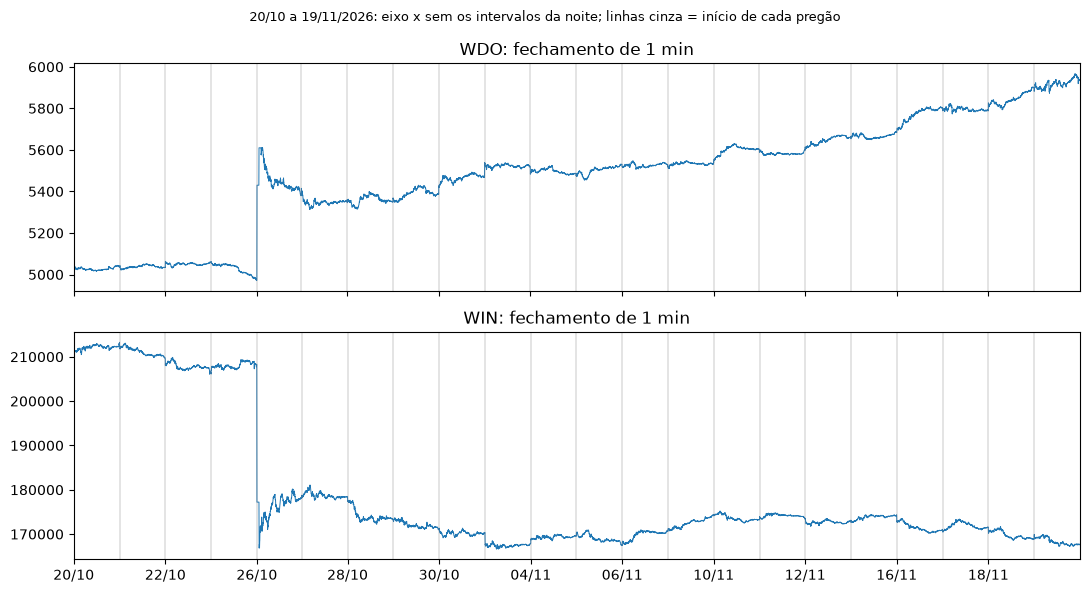

In [11]:
FIG = ROOT / "figures"
FIG.mkdir(exist_ok=True)

fig, axes = plt.subplots(2, 1, figsize=(11, 6))
for ax, (root, b) in zip(axes, bars.items()):
    ax.plot(range(len(b)), b["close"].values, lw=0.7)
    day = b.index.normalize()
    starts = np.flatnonzero(day.to_series().diff().ne(pd.Timedelta(0)))
    for s in starts:
        ax.axvline(s, color="grey", lw=0.3)
    ax.set_xticks(starts[::2], [d.strftime("%d/%m") for d in day[starts][::2]])
    ax.set_xlim(0, len(b))
    ax.set_title(f"{root}: fechamento de 1 min")
axes[0].tick_params(labelbottom=False)
fig.suptitle(f"{day.min():%d/%m} a {day.max():%d/%m/%Y}: eixo x sem os intervalos da noite; linhas cinza = início de cada pregão", fontsize=9)
plt.tight_layout()
fig.savefig(FIG / "precos_wdo_win.png", dpi=120)

## 2. Perfil intradiário do volume
A hipótese é um formato de "U", com mais volume na abertura e no fechamento.

Text(0.5, 1.0, 'Volume mediano por minuto do dia')

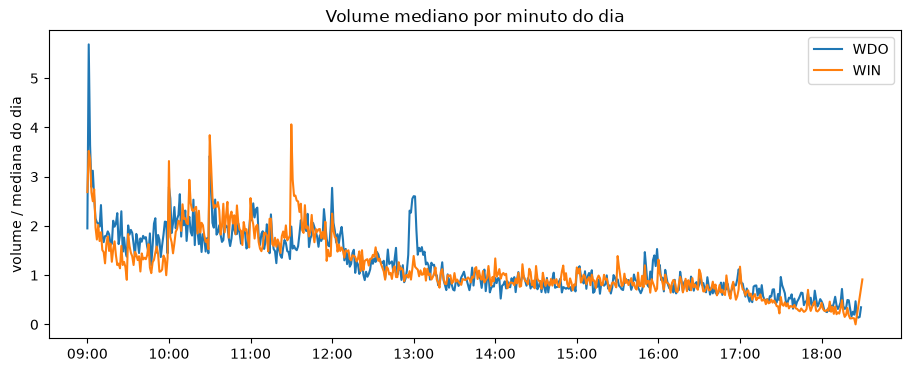

In [12]:
fig, ax = plt.subplots()
for root, b in bars.items():
    prof = b.groupby(b.index.strftime("%H:%M"))["volume"].median()
    ax.plot(prof.index, prof / prof.median(), label=root)
ax.set_xticks(ax.get_xticks()[::60]); ax.set_ylabel("volume / mediana do dia"); ax.legend()
ax.set_title("Volume mediano por minuto do dia")

In [13]:
faixas = [9, 9.5, 10, 12, 14, 16, 17.5, 18 + 35 / 60]
nomes = ["09:00-09:30", "09:30-10:00", "10:00-12:00", "12:00-14:00", "14:00-16:00", "16:00-17:30", "17:30-fim"]
minutos = pd.Series(np.diff(faixas) * 60, index=nomes)
tab = {}
for root, b in bars.items():
    faixa = pd.cut(b.index.hour + b.index.minute / 60, faixas, right=False, labels=nomes)
    vol = b["volume"].groupby([b.index.normalize(), faixa], observed=True).sum()
    share = vol / vol.groupby(level=0).transform("sum")            # fração do volume de cada dia
    pct = share.groupby(level=1, observed=True).mean() * 100        # média dos pregões, soma 100%
    intensidade = (pct / minutos) / (100 / minutos.sum())           # 1,0 = minuto médio do dia
    tab[(root, "% do volume do dia")] = pct.round(1)
    tab[(root, "intensidade (1,0 = média)")] = intensidade.round(2)
pd.DataFrame(tab).rename_axis("faixa de horário")  # a coluna "% do volume do dia" soma 100%

WDO                            \
                 % do volume do dia intensidade (1,0 = média)   
faixa de horário                                                
09:00-09:30                     9.2                      1.76   
09:30-10:00                     7.2                      1.38   
10:00-12:00                    32.0                      1.53   
12:00-14:00                    21.6                      1.03   
14:00-16:00                    15.3                      0.73   
16:00-17:30                    10.3                      0.66   
17:30-fim                       4.5                      0.40   

                                WIN                            
                 % do volume do dia intensidade (1,0 = média)  
faixa de horário                                               
09:00-09:30                     7.4                      1.42  
09:30-10:00                     6.0                      1.16  
10:00-12:00                    35.6                      1.70  
12:00-14:00                    21.0                      1.01  
14:00-16:00                    16.8                      0.80  
16:00-17:30                    10.1                      0.65  
17:30-fim                       3.1                      0.27

## 3. Distribuição dos retornos de 1 minuto
Retornos financeiros costumam ter **caudas gordas**, ou seja, curtose bem acima de 3 (o valor da normal).

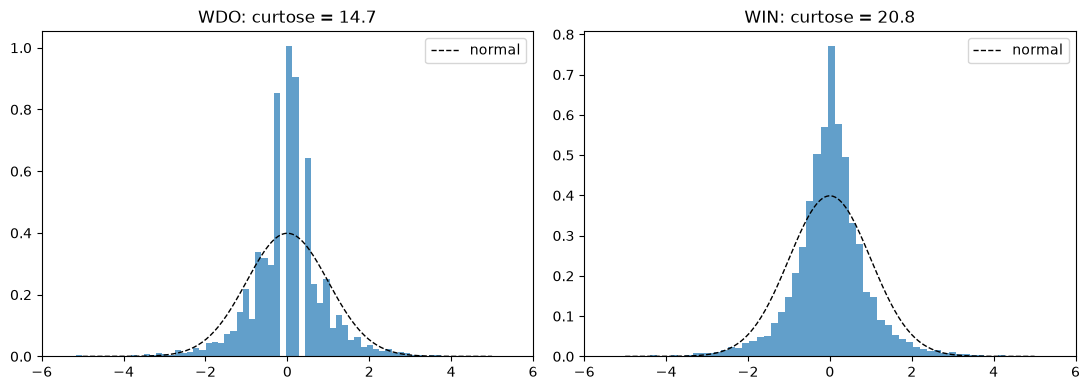

In [14]:
fig, axes = plt.subplots(1, 2)
for ax, (root, b) in zip(axes, bars.items()):
    r = b["ret"].dropna()
    ax.hist(r / r.std(), bins=150, density=True, alpha=0.7)
    x = np.linspace(-5, 5, 200); ax.plot(x, np.exp(-x**2 / 2) / np.sqrt(2 * np.pi), "k--", lw=1, label="normal")
    ax.set_xlim(-6, 6); ax.set_title(f"{root}: curtose = {r.kurt() + 3:.1f}"); ax.legend()
plt.tight_layout()

A assimetria e a curtose são sensíveis a poucos pontos extremos, então vale comparar com e sem 26/10. Também há um choque em 19/11: às 12:03, o WDO caiu 47 bps em um minuto, com 9 vezes o volume normal, e mais 30 bps no minuto seguinte. É o maior movimento de 1 minuto da amostra, maior até que os de 26/10.

In [15]:
def momentos(b):
    r = b["ret"].dropna()
    return pd.Series({"curtose": r.kurt() + 3, "assimetria": r.skew(), "n": len(r)})

sem_26 = {k: v[v.index.normalize() != "2026-10-26"] for k, v in bars.items()}
pd.concat({"todos os pregões": pd.DataFrame({k: momentos(v) for k, v in bars.items()}),
           "sem 26/10": pd.DataFrame({k: momentos(v) for k, v in sem_26.items()})}).round(2)

WDO       WIN
todos os pregões curtose        14.66     20.78
                 assimetria     -0.48     -0.11
                 n           12500.00  12384.00
sem 26/10        curtose        15.08     15.40
                 assimetria     -0.42     -0.71
                 n           11949.00  11833.00

## 4. Autocorrelação
Uma autocorrelação negativa no lag 1 costuma vir do *bid-ask bounce*: o preço alterna entre negócios no bid e no ask.

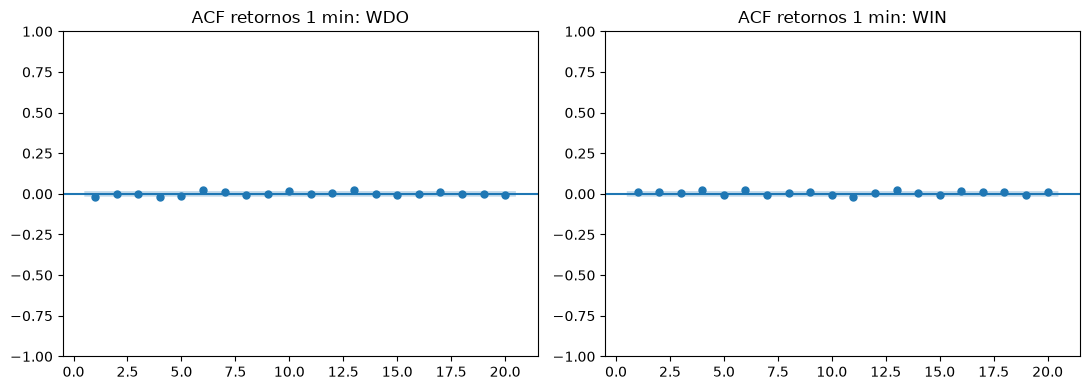

In [16]:
fig, axes = plt.subplots(1, 2)
for ax, (root, b) in zip(axes, bars.items()):
    plot_acf(b["ret"], missing="conservative", lags=20, ax=ax, title=f"ACF retornos 1 min: {root}", zero=False)
plt.tight_layout()

Duas autocorrelações diferentes:
- **ret:** a *direção* do minuto anterior ajuda a prever a do próximo?
- **|ret|:** a *intensidade* do movimento se repete? Se sim, a volatilidade se aglomera, com minutos agitados seguidos de minutos agitados.

Valores dentro da banda de 95% (±1,96/√n) não são distinguíveis de zero. **Cuidado:** essa banda supõe variância constante. Com a volatilidade aglomerada, que é justamente o que o |ret| mostra, ela fica estreita demais, e é o mesmo problema que o HAC corrige nas regressões (próxima célula).

O cálculo não emenda o último minuto de um pregão no primeiro do seguinte: os pares que atravessam a noite ou um leilão ficam de fora (`missing="conservative"`).

In [17]:
from statsmodels.tsa.stattools import acf

rows = []
for nome, conjunto in [("todos os pregões", bars), ("sem 26/10", sem_26)]:
    for root, b in conjunto.items():
        r = b["ret"]  # sem dropna: os NaN do início de cada trecho impedem emendar um pregão no outro
        a, a_abs = acf(r, nlags=3, missing="conservative"), acf(r.abs(), nlags=3, missing="conservative")
        rows.append({"amostra": nome, "ativo": root, "ret lag1": a[1], "ret lag2": a[2], "ret lag3": a[3],
                     "|ret| lag1": a_abs[1], "|ret| lag3": a_abs[3], "banda 95%": 1.96 / np.sqrt(r.notna().sum())})
pd.DataFrame(rows).set_index(["amostra", "ativo"]).round(3)

ret lag1  ret lag2  ret lag3  |ret| lag1  |ret| lag3  \
amostra          ativo                                                         
todos os pregões WDO      -0.022    -0.001    -0.001       0.289       0.238   
                 WIN       0.011     0.009     0.005       0.332       0.301   
sem 26/10        WDO      -0.031    -0.014    -0.003       0.227       0.175   
                 WIN      -0.025    -0.005    -0.022       0.223       0.186   

                        banda 95%  
amostra          ativo             
todos os pregões WDO        0.018  
                 WIN        0.018  
sem 26/10        WDO        0.018  
                 WIN        0.018

Sem 26/10, o lag 1 do retorno fica fora da banda nos dois ativos. Para saber se isso é real, refazemos o mesmo teste como regressão (retorno do próximo minuto contra o deste) com dois erros-padrão: o comum, que supõe variância constante e erros independentes, e o HAC.

In [18]:
rows = []
for nome, conjunto in [("todos os pregões", bars), ("sem 26/10", sem_26)]:
    for root, b in conjunto.items():
        d = b[["ret", "fwd_ret_1"]].dropna() * 1e4
        comum = smf.ols("fwd_ret_1 ~ ret", d).fit()
        hac = smf.ols("fwd_ret_1 ~ ret", d).fit(cov_type="HAC", cov_kwds={"maxlags": 5})
        rows.append({"amostra": nome, "ativo": root, "beta": comum.params["ret"], "t comum": comum.tvalues["ret"],
                     "t HAC": hac.tvalues["ret"], "R² (%)": 100 * comum.rsquared})
pd.DataFrame(rows).set_index(["amostra", "ativo"]).round(3)

beta  t comum  t HAC  R² (%)
amostra          ativo                               
todos os pregões WDO   -0.022   -2.522 -1.273   0.051
                 WIN    0.011    1.260  0.553   0.013
sem 26/10        WDO   -0.031   -3.397 -1.852   0.097
                 WIN   -0.025   -2.746 -1.412   0.064

**O que os números mostram**
- O HAC reduz o |t| quase pela metade: sem 26/10, o do WDO vai de −3,4 para −1,9 e o do WIN de −2,7 para −1,4. Pela banda do ACF, o lag 1 parecia significativo; com o HAC, nenhum dos dois é.
- O que aparece no WDO é uma **reversão** pequena. Depois de um minuto de alta, o minuto seguinte devolve em média 3% do movimento, o que explica 0,1% da variância. É coerente com o *bid-ask bounce* (ver [glossário](../GLOSSARIO.md#bid-ask-bounce)).
- Economicamente, é irrelevante. Num minuto típico de ~3 bps, 3% dá ~0,1 bp, contra ~0,9 bp de 1 tick do WDO.
- Com 20 pregões, o t HAC do WDO sem 26/10 era −2,6. Dois pregões a mais bastaram para ele cair para −1,9, mais um sinal de que o efeito é frágil.

## 5. Fluxo de agressão → retorno seguinte (prévia do Cap. 3)
`imbalance` = (volume comprador − vendedor) / volume. O lado de cada negócio é estimado pela *tick rule*, porque o arquivo público não informa o agressor.

A correlação **no mesmo minuto** é quase mecânica: a tick rule usa o próprio preço. Para predição, o que interessa é o **minuto seguinte** (`fwd_ret_1`).
Os erros-padrão são HAC (Newey-West), robustos à autocorrelação e à heterocedasticidade que os retornos têm.

In [19]:
rows = []
for root, b in bars.items():
    d = b[["imbalance", "ret", "fwd_ret_1"]].dropna() * [1, 1e4, 1e4]  # retornos em bps
    same = smf.ols("ret ~ imbalance", d).fit(cov_type="HAC", cov_kwds={"maxlags": 5})
    nxt = smf.ols("fwd_ret_1 ~ imbalance", d).fit(cov_type="HAC", cov_kwds={"maxlags": 5})
    rows.append({"ativo": root, "n": len(d),
                 "mesmo min: beta (bps)": same.params["imbalance"], "mesmo min: t": same.tvalues["imbalance"], "mesmo min: R2": same.rsquared,
                 "próx. min: beta (bps)": nxt.params["imbalance"], "próx. min: t": nxt.tvalues["imbalance"], "próx. min: R2": nxt.rsquared})
pd.DataFrame(rows).set_index("ativo").round(4)

,n,mesmo min: beta (bps),mesmo min: t,mesmo min: R2,próx. min: beta (bps),próx. min: t,próx. min: R2
ativo,,,,,,,
WDO,12477,5.2918,46.3113,0.2493,-0.029,-0.3656,0.0000
WIN,12361,22.8866,56.2406,0.3971,-0.406,-1.5999,0.0001


### Isso afeta o `imbalance`?

A tick rule atribui um lado a **todo** negócio. Num negócio direto, que é no preço da tela e sem agressor, ela só repete o sinal do negócio anterior. Um negócio direto de 30 mil contratos vira uma "agressão" de 30 mil, num minuto em que o WDO negocia em média uns 6 mil.

Por isso o pipeline calcula o fluxo em duas versões: `imbalance`, com todos os negócios, e `imbalance_sem_diretos`, sem os **prováveis** negócios diretos. O arquivo público não marca os diretos, então a identificação é uma proxy montada com as regras da B3 para oferta direta (`direct_trade_proxy` em `src/features.py`):
- **mesma corretora** como compradora e vendedora, porque a oferta direta é registrada "pelo mesmo participante, representando o cliente comprador e o cliente vendedor";
- **pelo menos 500 contratos**, o lote mínimo de oferta direta no WDO e no WIN (B3, Ofício Circular 176/2022-PRE; a B3 revisa esse valor);
- **fora dos leilões** (primeiros 50 ms de cada trecho de negociação), porque a B3 rejeita oferta direta durante leilão.

A proxy pode errar para os dois lados. Ela marca por engano um negócio grande em que a corretora só agrediu uma oferta de outro cliente dela no livro, e deixa passar um direto que tenha saído no meio de um leilão (o que a regra não permite).

In [20]:
rows = []
for root, b in bars.items():
    afetadas = b["n_diretos"] > 0
    d = b[["imbalance", "imbalance_sem_diretos", "ret", "fwd_ret_1"]].dropna().copy()
    d[["ret", "fwd_ret_1"]] *= 1e4
    linha = {"ativo": root, "negócios diretos (proxy)": int(b["n_diretos"].sum()),
             "% do volume": 100 * b["volume_direto"].sum() / b["volume"].sum(),
             "barras afetadas": int(afetadas.sum()),
             "mudança média do imbalance nelas": (b["imbalance"] - b["imbalance_sem_diretos"])[afetadas].abs().mean(),
             "corr(com, sem diretos)": d["imbalance"].corr(d["imbalance_sem_diretos"])}
    for col, nome in [("imbalance", "com diretos"), ("imbalance_sem_diretos", "sem diretos")]:
        linha[f"R² mesmo min, {nome} (%)"] = 100 * smf.ols(f"ret ~ {col}", d).fit().rsquared
        linha[f"t próx. min, {nome}"] = smf.ols(f"fwd_ret_1 ~ {col}", d).fit(cov_type="HAC", cov_kwds={"maxlags": 5}).tvalues[col]
    rows.append(linha)
pd.DataFrame(rows).set_index("ativo").round(3).T

ativo,WDO,WIN
negócios diretos (proxy),843.000,340.000
% do volume,2.280,0.167
barras afetadas,777.000,293.000
mudança média do imbalance nelas,0.208,0.079
"corr(com, sem diretos)",0.973,0.993
"R² mesmo min, com diretos (%)",24.929,39.713
"t próx. min, com diretos",-0.366,-1.600
"R² mesmo min, sem diretos (%)",26.363,40.138
"t próx. min, sem diretos",-0.141,-1.464


**O que os números mostram**
- **WDO:** a proxy marca 843 negócios (2,3% do volume), espalhados por 777 minutos. Nesses minutos, o `imbalance` muda 0,21 em média numa escala de −1 a +1, e às vezes muito mais (o negócio de 30 mil contratos inverte o sinal do minuto). No conjunto, a correlação entre as duas versões é 0,97.
- **WIN:** o efeito é bem menor (0,2% do volume, mudança média de 0,08), porque no WIN os negócios grandes de mesma corretora são quase todos de leilão, que a proxy exclui.
- **As conclusões não mudam.** O poder preditivo para o minuto seguinte continua nulo nas duas versões (|t| < 2). O R² do mesmo minuto sobe um pouco sem os diretos (de 24,9% para 26,4% no WDO), o que é coerente com eles serem ruído para a tick rule.
- **Para os próximos capítulos:** as duas versões ficam disponíveis nas barras. Como a proxy pode errar, vale testar os modelos com as duas e ver se o resultado depende da escolha.

## 6. WDO × WIN
Dólar e bolsa costumam andar em sentidos opostos: na fuga de risco, o dólar sobe e o índice cai. A pergunta é se essa relação se mantém estável de um dia para o outro.

corr(ret WDO, ret WIN) em 1 min, período todo = -0.457


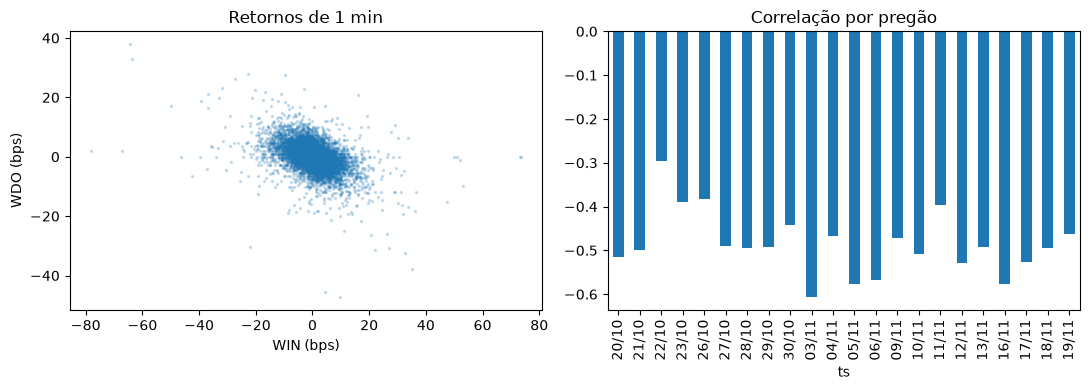

In [21]:
both = pd.concat({k: v["ret"] for k, v in bars.items()}, axis=1).dropna()
print(f"corr(ret WDO, ret WIN) em 1 min, período todo = {both.corr().iloc[0, 1]:+.3f}")
por_dia_corr = both.groupby(both.index.normalize()).apply(lambda g: g["WDO"].corr(g["WIN"]))
fig, axes = plt.subplots(1, 2)
axes[0].scatter(both["WIN"] * 1e4, both["WDO"] * 1e4, s=2, alpha=0.2); axes[0].set_xlabel("WIN (bps)"); axes[0].set_ylabel("WDO (bps)")
axes[0].set_title("Retornos de 1 min")
por_dia_corr.plot.bar(ax=axes[1], title="Correlação por pregão"); axes[1].set_xticklabels([d.strftime("%d/%m") for d in por_dia_corr.index])
plt.tight_layout()

### Um ativo antecipa o outro? E quantos testes fizemos?

Correlação no mesmo minuto não serve para prever. A pergunta útil é de **antecipação** (*lead-lag*): o retorno de um ativo agora ajuda a prever o do outro nos próximos minutos?

Para não olhar só o resultado mais bonito, a tabela abaixo registra **todos** os testes feitos: 2 ativos × 3 horizontes (1, 5 e 15 minutos à frente) × 3 preditores, num total de 18 regressões:
- `imbalance`: o fluxo de agressão do minuto;
- `ret`: o retorno do próprio ativo no minuto (continuação ou reversão);
- `ret_outro`: o retorno do **outro** ativo no minuto (antecipação).

Os retornos de 5 e 15 minutos se **sobrepõem**: o retorno de 9h00–9h05 e o de 9h01–9h06 compartilham 4 minutos. Isso cria autocorrelação nos erros por construção, e por isso o HAC usa `maxlags` = horizonte + 5.

Com 18 testes, |t| > 1,96 não basta. A **correção de Bonferroni** exige |t| > 2,99 para manter 5% de chance de *algum* falso positivo.

In [22]:
from scipy.stats import norm

testes = []
for root, b in bars.items():
    outro = "WIN" if root == "WDO" else "WDO"
    x = b[["close", "ret", "imbalance"]].join(bars[outro]["ret"].rename("ret_outro"))
    for h in [1, 5, 15]:
        x = add_forward_return(x, h)   # não atravessa pregões nem leilões
    for h in [1, 5, 15]:
        y = f"fwd_ret_{h}"
        for f in ["imbalance", "ret", "ret_outro"]:
            d = x[[y, f]].dropna()
            d[y] *= 1e4                                   # bps
            if f != "imbalance":
                d[f] *= 1e4
            m = smf.ols(f"{y} ~ {f}", d).fit(cov_type="HAC", cov_kwds={"maxlags": h + 5})
            testes.append({"ativo previsto": root, "horizonte (min)": h, "preditor": f, "beta": m.params[f],
                           "t": m.tvalues[f], "R² (%)": 100 * m.rsquared, "n": int(m.nobs)})
testes = pd.DataFrame(testes)
t_bonf = norm.ppf(1 - 0.05 / (2 * len(testes)))
testes["|t| > 1,96"] = testes["t"].abs() > 1.96
testes[f"|t| > {t_bonf:.2f} (Bonferroni)"] = testes["t"].abs() > t_bonf
print(f"{len(testes)} testes; limite de Bonferroni: |t| > {t_bonf:.2f}")
testes.round(3)

18 testes; limite de Bonferroni: |t| > 2.99


,ativo previsto,horizonte (min),preditor,beta,t,R² (%),n,"|t| > 1,96",|t| > 2.99 (Bonferroni)
0,WDO,1,imbalance,-0.026,-0.321,0.001,12500,False,False
1,WDO,1,ret,-0.022,-1.280,0.051,12477,False,False
2,WDO,1,ret_outro,0.004,0.488,0.004,12379,False,False
3,WDO,5,imbalance,-0.162,-0.657,0.005,12408,False,False
4,WDO,5,ret,-0.053,-1.608,0.061,12385,False,False
5,WDO,5,ret_outro,0.020,0.928,0.021,12374,False,False
6,WDO,15,imbalance,0.430,0.945,0.012,12178,False,False
7,WDO,15,ret,0.008,0.131,0.000,12155,False,False
8,WDO,15,ret_outro,-0.027,-0.615,0.013,12144,False,False
9,WIN,1,imbalance,-0.383,-1.514,0.011,12384,False,False


**O que os números mostram**
- Só 1 dos 18 testes passa de |t| > 1,96, e por pouco: o fluxo do WIN "prevendo" o retorno dos 5 minutos seguintes (t = −2,00). Com 18 testes e 5% de chance cada, o acaso sozinho produziria em média 0,9 "significativo". Então 1 é exatamente o esperado.
- Esse teste **não sobrevive** à correção de Bonferroni (|t| > 2,99). Não há evidência de que um ativo antecipe o outro em 1 a 15 minutos, nem de que o fluxo ou o próprio retorno prevejam os próximos minutos.
- **O falso positivo mudou de lugar.** Com 20 pregões, o teste que passava de 1,96 era outro: o retorno do WDO "prevendo" o do WIN no minuto seguinte (t = −2,7). Com 2 pregões a mais, ele caiu para −1,7, e o fluxo do WIN subiu para −2,0. Um efeito real tenderia a se manter quando a amostra cresce. Já um falso positivo aparece e some de um teste para outro.
- Os R² ficam todos abaixo de 0,1%.
- Este é o tema do cap. 13 do ISLP (testes múltiplos), e o motivo de registrar *todos* os testes, não só o melhor.

## Conclusões

**Amostra:** 22 pregões, de 20/10 a 19/11/2026, com o vencimento principal de WDO e WIN e retornos em barras de 1 minuto.

**Visão geral da amostra:** o período tem um choque em 26/10, causado pelo resultado inesperado do segundo turno das eleições presidenciais ([CNN Brasil](https://www.cnnbrasil.com.br/blogs/lucinda-pinto/economia/money/mercado/vitoria-de-lula-surpreende-mercado-e-coloca-pesquisas-eleitorais-em-questao/), [g1](https://g1.globo.com/jornal-nacional/noticia/2026/10/26/mercado-financeiro-reage-a-vitoria-de-lula-com-queda-da-bolsa-de-valores-e-alta-do-dolar.ghtml)). Do fechamento de sexta para a abertura de segunda, o dólar subiu forte e o índice caiu forte (WDO +9,2%, WIN −14,9%). Depois disso, o dólar seguiu em alta e o índice ficou de lado em um patamar mais baixo. Os dois ativos se moveram em sentidos opostos também na escala de semanas.

**Negócio:** execução entre uma corretora compradora e uma vendedora. Uma ordem agressora gera vários negócios no mesmo milissegundo: cerca de 80% dos negócios dividem o milissegundo com outro, e a maior rajada chegou a 4.379 negócios do WIN em 1 ms (05/11). A maioria dos negócios é de 1 contrato (59% no WIN, 67% no WDO), mas eles movimentam só 15–19% do volume. No WDO, os negócios de 11 contratos ou mais são menos de 8% do total e carregam ~60% dos contratos. O tamanho tem cauda longa: os 1% maiores negócios carregam 24% do volume do WDO e 14% do WIN. Os negócios gigantes (até 30 mil contratos) têm as características de ofertas diretas pela regra da B3: a mesma corretora dos dois lados, no preço da tela e fora de leilão. O WIN ainda tem um leilão de fechamento diário às 18:31, com 800 a 3.100 negócios num único preço. Acima de 5.000 contratos, 97–100% dos negócios têm a mesma corretora dos dois lados, e nenhum sai do leilão de abertura. Nem os diretos nem os leilões mudam as conclusões sobre fluxo e preço: as barras trazem o `imbalance` com e sem os prováveis diretos, e os resultados são os mesmos.

**Volume:** concentrado na manhã, com pico na abertura no WDO e entre 10h e 12h no WIN. Cai ao longo da tarde e não tem formato de "U". Os horários de maior volume coincidem com os de maior volatilidade.

**Retornos:** caudas gordas (curtose 15 no WDO e 21 no WIN). A curtose e a assimetria dependem de poucos minutos extremos: 26/10 e, no WDO, a queda de 47 bps em 1 minuto às 12:03 de 19/11. A direção quase não tem autocorrelação. O WDO mostra uma reversão pequena de um minuto para o outro, que não é significativa com erros HAC (t = −1,9 sem 26/10) e é economicamente irrelevante (~0,1 bp, contra ~0,9 bp de 1 tick). A volatilidade se aglomera: a autocorrelação de |ret| fica entre 0,29 e 0,33 com todos os pregões e em ~0,22 sem 26/10. WDO e WIN têm correlação de −0,46 no mesmo minuto, sem um antecipar o outro: dos 18 testes registrados, só 1 passa de |t| > 1,96, e ele não sobrevive à correção de Bonferroni. O teste que passava com 20 pregões deixou de passar com 22, o comportamento típico de um falso positivo.

**Fluxo → preço:** forte no mesmo minuto, mas por construção da tick rule. Para o minuto seguinte, não há poder preditivo nesta amostra.